# M03-L02 — Datasets tabulares, pré-processamento e preparação de dados

Bem-vindo(a) de volta! Este notebook dá continuidade direta à M03-L01.

Nesta lição, você vai carregar o Iris de verdade, a partir de um arquivo `.csv`, e prepará-lo com `pandas` para o treinamento dos primeiros classificadores, que acontecerá na M03-L03.

Os seguintes arquivos devem estar na mesma pasta deste notebook (ou no seu Google Drive, se você preferir montar o Drive):

- `iris.csv`
- `iris_desbalanceado.csv`
- `iris_sujo.csv`

**Antes de começar:** salve uma cópia deste notebook no seu Google Drive (`Arquivo > Salvar uma cópia no Drive`), para não perder o seu progresso.

In [18]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Retomando a M03-L01

Na lição passada, o Iris era uma lista de dicionários, digitada à mão:

```python
iris_manual = [
    {"comprimento_petala": 1.4, "largura_petala": 0.2, "especie": "setosa"},
    {"comprimento_petala": 4.7, "largura_petala": 1.4, "especie": "versicolor"},
    # ... mais amostras
]
```

E um classificador manual, feito só com `if`/`else`, tentava prever a espécie — acertando algumas flores, errando outras, por não conseguir generalizar bem.

Hoje, essa mesma informação vem de um arquivo `iris.csv` real, e o pandas assume o trabalho pesado de organizar, contar e limpar os dados.

## Exemplo guiado 1 — Carregando o Iris com pandas

Vamos importar o pandas e carregar o arquivo `iris.csv`.

In [20]:
import pandas as pd

df = pd.read_csv("iris.csv")
df.head()

,id_da_planta,data_coleta,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,especie
0,P001,2024-05-05,6.1,2.8,4.7,1.2,versicolor
1,P002,2024-06-04,5.7,3.8,1.7,0.3,setosa
2,P003,2024-05-30,7.7,2.6,6.9,2.3,virginica
3,P004,2024-05-20,6.0,2.9,4.5,1.5,versicolor
4,P005,2024-05-20,6.8,2.8,4.8,1.4,versicolor


`read_csv` leu o arquivo de texto, separou cada linha pelas vírgulas e montou a tabela automaticamente. `head()` mostra as cinco primeiras linhas — a versão automática de "olhar" a lista de dicionários da M03-L01.

## Exercício 1 — Inspecionando a estrutura

Use `shape`, `dtypes` e `columns` sobre `df` nas células abaixo. Depois, em uma célula de texto, escreva o que cada resultado significa: quantas linhas e colunas o dataset tem, quais os tipos de cada coluna e quais são os nomes das colunas.

In [21]:
df.shape


(150, 7)

In [22]:
df.dtypes


,0
id_da_planta,object
data_coleta,object
comprimento_sepala,float64
largura_sepala,float64
comprimento_petala,float64
largura_petala,float64
especie,object


In [24]:
df.columns

Index(['id_da_planta', 'data_coleta', 'comprimento_sepala', 'largura_sepala',
       'comprimento_petala', 'largura_petala', 'especie'],
      dtype='object')

**Sua resposta em texto:**

df.shape - retorna as linhas e colunas.
df.dtypes - retorna os nomes das colunas e seu tipo.
df.columns - retorna os nomes das colunas em forma de vetor.

## Exemplo guiado 2 — Coluna-alvo e colunas identificadoras

A coluna-alvo do Iris é `especie`. As colunas `id_da_planta` e `data_coleta`, que você já tinha identificado como inúteis na M03-L01, aparecem de verdade aqui — e vamos removê-las.

In [25]:
df = df.drop(columns=["id_da_planta", "data_coleta"])
df.head()

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,especie
0,6.1,2.8,4.7,1.2,versicolor
1,5.7,3.8,1.7,0.3,setosa
2,7.7,2.6,6.9,2.3,virginica
3,6.0,2.9,4.5,1.5,versicolor
4,6.8,2.8,4.8,1.4,versicolor


`drop(columns=[...])` devolve a tabela sem as colunas indicadas. Note que precisamos reatribuir o resultado a `df`, porque `drop()` não altera a tabela original por padrão.

## Exercício 2 — Removendo uma coluna identificadora extra

O arquivo `iris_variante.csv` (fornecido junto a este notebook) tem uma coluna identificadora adicional chamada `codigo_lote`. Carregue esse arquivo em uma nova variável e remova essa coluna. Em seguida, escreva em texto por que `codigo_lote` não deve ser tratada como feature.

In [29]:
import pandas as pd
df_variante = pd.read_csv("iris_variante.csv")
df_variante = df_variante.drop(columns=["codigo_lote"])
df_variante.head()

,id_da_planta,data_coleta,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,especie
0,P001,2024-05-05,6.1,2.8,4.7,1.2,versicolor
1,P002,2024-06-04,5.7,3.8,1.7,0.3,setosa
2,P003,2024-05-30,7.7,2.6,6.9,2.3,virginica
3,P004,2024-05-20,6.0,2.9,4.5,1.5,versicolor
4,P005,2024-05-20,6.8,2.8,4.8,1.4,versicolor


**Sua justificativa em texto:**

O codigo_lote não deve ser tratado como uma feature, pois é um identificador, e não é um dado em si que representa algo sobre a planta.

## Exemplo guiado 3 — Separando X e y, contando e visualizando classes

In [26]:
X = df.drop(columns=["especie"])
y = df["especie"]

y.value_counts()

,count
especie,
versicolor,50
setosa,50
virginica,50


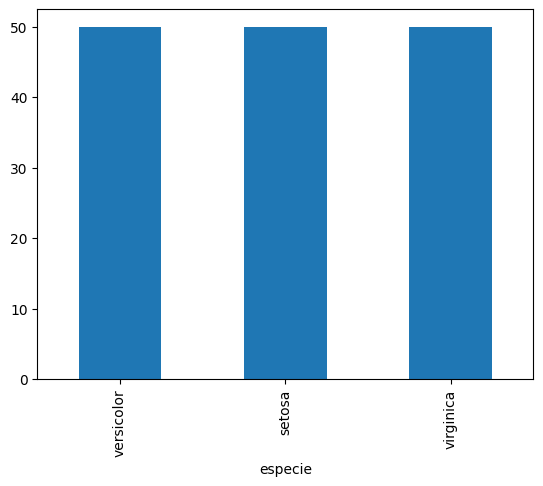

In [27]:
import matplotlib.pyplot as plt

y.value_counts().plot(kind="bar")
plt.show()

`value_counts()` conta quantas amostras existem de cada espécie — a versão automática do dicionário de contagem que você montou manualmente na M03-L01. O gráfico de barras mostra essa mesma distribuição de forma visual.

## Exercício 3 — Classes em um dataset desbalanceado

Carregue `iris_desbalanceado.csv`, repita a contagem de classes com `value_counts()` e gere um gráfico de barras. Depois, escreva em texto se o dataset está balanceado ou desbalanceado, retomando a discussão da M03-L01.

especie
setosa        50
versicolor    40
virginica     10
Name: count, dtype: int64


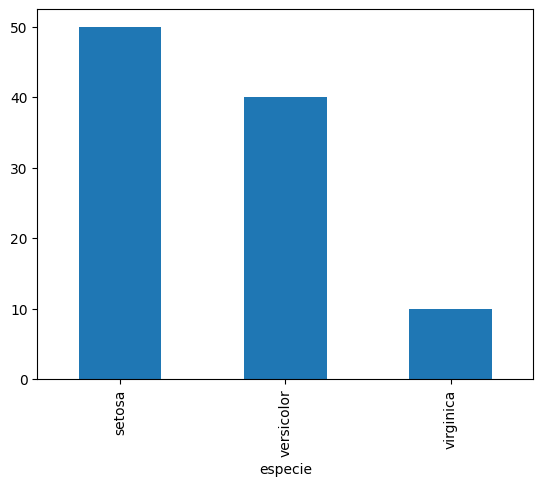

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

df_desbalanceado = pd.read_csv("iris_desbalanceado.csv")
y_desbalanceado = df_desbalanceado["especie"]
print(y_desbalanceado.value_counts())
y_desbalanceado.value_counts().plot(kind="bar")
plt.show()


**Sua resposta em texto:**

está desbalanceado, pois há uma diferença até que significativa entre as especies, o tornando desbalancieado.

## Exemplo guiado 4 — Detectando e tratando valores ausentes

In [31]:
df_sujo = pd.read_csv("iris_sujo.csv")
df_sujo.isnull().sum()

,0
id_da_planta,0
data_coleta,0
comprimento_sepala,0
largura_sepala,4
comprimento_petala,7
largura_petala,0
especie,0


In [32]:
df_sem_na = df_sujo.dropna()
df_sem_na.isnull().sum()

,0
id_da_planta,0
data_coleta,0
comprimento_sepala,0
largura_sepala,0
comprimento_petala,0
largura_petala,0
especie,0


`isnull().sum()` conta quantos valores ausentes existem em cada coluna. `dropna()` remove as linhas incompletas. Também existe `fillna()`, que preenche o valor ausente em vez de remover a linha — útil quando há poucos dados e não se quer perder amostras.

## Exercício 4 — Tratando valores ausentes

Usando `df_sujo`, detecte os valores ausentes e trate-os com `dropna()` **ou** `fillna()`. Explique em texto qual opção você escolheu e por quê.

In [74]:
print("Valores nulos antes do tratamento:")
print(df_sujo.isnull().sum())
df_limpo = df_sujo.dropna()
print("\nValores nulos após o tratamento:")
print(df_limpo.isnull().sum())

Valores nulos antes do tratamento:
id_da_planta          0
data_coleta           0
comprimento_sepala    0
largura_sepala        4
comprimento_petala    6
largura_petala        0
especie               0
dtype: int64

Valores nulos após o tratamento:
id_da_planta          0
data_coleta           0
comprimento_sepala    0
largura_sepala        0
comprimento_petala    0
largura_petala        0
especie               0
dtype: int64


**Sua justificativa em texto:**

Usei o método dropna(), pois os dados nulos é muito menor do que comparado com os outros dados existentes.

## Exemplo guiado 5 — Detectando e removendo duplicados

In [33]:
df_sujo.duplicated().sum()

np.int64(5)

In [36]:
df_sem_dup = df_sujo.drop_duplicates()
df_sem_dup.duplicated().sum()

np.int64(0)

## Exercício 5 — Removendo duplicados

Detecte e remova as linhas duplicadas em `iris_sujo.csv` (pode reaproveitar a variável `df_sujo`, se ainda não tiver salvo o resultado do exercício anterior sobre ela).

In [73]:
print("Duplicadas antes da limpeza:", df_sujo.duplicated().sum())
df_sujo = df_sujo.drop_duplicates()
print("Duplicadas após a limpeza:", df_sujo.duplicated().sum())

Duplicadas antes da limpeza: 0
Duplicadas após a limpeza: 0


## Exemplo guiado 6 — Corrigindo tipos incorretos e valores inconsistentes

In [48]:
df_sujo["comprimento_petala"] = df_sujo["comprimento_petala"]
df_sujo["especie"] = df_sujo["especie"].str.lower()
df_sujo.dtypes

,0
id_da_planta,object
data_coleta,object
comprimento_sepala,float64
largura_sepala,float64
comprimento_petala,float64
largura_petala,float64
especie,object


`astype(float)` converte a coluna para número decimal. `.str.lower()` uniformiza o texto da coluna `especie`, evitando que `"Setosa"` e `"setosa"` sejam tratadas como categorias diferentes.

## Exercício 6 — Corrigindo tipo e inconsistência

Em `iris_sujo.csv`, verifique se existe alguma coluna numérica armazenada como texto. Se houver, converta-a para o tipo numérico adequado. Em seguida, identifique um valor de categoria escrito de forma inconsistente e corrija-o.

In [99]:
print(df_sujo.dtypes)

df_sujo["largura_petala"] = df_sujo["largura_petala"].astype(float)
df_sujo["especie"] = df_sujo["especie"].str.lower()

id_da_planta           object
data_coleta            object
comprimento_sepala    float64
largura_sepala        float64
comprimento_petala    float64
largura_petala        float64
especie                object
dtype: object


## Exemplo guiado 7 — Normalização e padronização

In [96]:
coluna = df["comprimento_petala"]

df["comprimento_petala_norm"] = (coluna - coluna.min()) / (coluna.max() - coluna.min())
df["comprimento_petala_pad"] = (coluna - coluna.mean()) / coluna.std()
df[["comprimento_petala", "comprimento_petala_norm", "comprimento_petala_pad"]].head()

,comprimento_petala,comprimento_petala_norm,comprimento_petala_pad
0,4.7,0.627119,0.533621
1,1.7,0.118644,-1.165809
2,6.9,1.000000,1.779869
3,4.5,0.593220,0.420326
4,4.8,0.644068,0.590269


A normalização reescala os valores para o intervalo de 0 a 1. A padronização centraliza os valores em zero, medidos em desvios padrão. Repare que os valores deixam de estar em centímetros — eles agora representam posição relativa dentro da escala escolhida.

## Exercício 7 — Normalizando ou padronizando outra coluna

Escolha uma coluna numérica diferente e aplique normalização **ou** padronização a ela. Em texto, interprete o resultado: os valores continuam fazendo sentido como medida em centímetros? Por quê?

In [71]:
coluna_largura = df["largura_sepala"]
df["largura_sepala_pad"] = (coluna_largura - coluna_largura.mean()) / coluna_largura.std()
df[["largura_sepala", "largura_sepala_pad"]].head()

,largura_sepala,largura_sepala_pad
0,2.8,-0.590395
1,3.8,1.703886
2,2.6,-1.049251
3,2.9,-0.360967
4,2.8,-0.590395


**Sua interpretação em texto:**

Não, porque a unidade de medida não serve para o pandas, pois a medida em centimetros é diferente da padronização, que reprenseta qual longe a amostra está distante da média.

## Exemplo guiado 8 — Amostragem e divisão treino/teste

In [42]:
df.sample(5)

,comprimento_sepala,largura_sepala,comprimento_petala,largura_petala,especie
36,6.4,3.2,4.5,1.5,versicolor
55,5.8,2.7,4.1,1.0,versicolor
127,6.7,3.3,5.7,2.1,virginica
120,6.1,3.0,4.6,1.4,versicolor
110,6.5,2.8,4.6,1.5,versicolor


In [93]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["especie"])
y = df["especie"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_treino.shape, X_teste.shape

((120, 7), (30, 7))

`sample(5)` mostra cinco linhas aleatórias da tabela. `train_test_split` embaralha e divide os dados em treino e teste, mantendo `X` e `y` sempre correspondentes. `test_size=0.2` reserva 20% dos dados para teste. `random_state=42` só garante que a divisão seja sempre a mesma ao reexecutar a célula.

## Exercício 8 — Dividindo com outra proporção

Divida o dataset novamente, agora usando `test_size=0.3`. Confira o tamanho resultante de `X_treino` e `X_teste` e compare com a divisão anterior.

In [94]:
X_treino_30, X_teste_30, y_treino_30, y_teste_30 = train_test_split(
    X, y, test_size=0.3, random_state=42
)

X_treino_30.shape, X_teste_30.shape

((105, 7), (45, 7))

## Exemplo de erro comum — dividir antes de remover colunas identificadoras

Veja o que acontece quando os dados são divididos em treino e teste **antes** de remover as colunas identificadoras:

In [95]:
df_bruto = pd.read_csv("iris.csv")

X_errado = df_bruto.drop(columns=["especie"])
y_errado = df_bruto["especie"]

X_treino_errado, X_teste_errado, y_treino_errado, y_teste_errado = train_test_split(
    X_errado, y_errado, test_size=0.2, random_state=42
)

X_treino_errado.columns

Index(['id_da_planta', 'data_coleta', 'comprimento_sepala', 'largura_sepala',
       'comprimento_petala', 'largura_petala'],
      dtype='object')

Note que `id_da_planta` e `data_coleta` ainda aparecem entre as colunas de `X_treino_errado` — elas "vazaram" como se fossem features, mesmo não carregando nenhuma informação real sobre a espécie da flor.

## Exercício de correção — refazendo na ordem certa

Refaça a preparação de `df_bruto`, agora na ordem correta: primeiro remova as colunas identificadoras, depois separe `X` e `y`, e só então divida em treino e teste. Confirme, ao final, que `X_treino` não contém mais `id_da_planta` nem `data_coleta`.

In [80]:
df_limpo = df_bruto.drop(columns=["id_da_planta", "data_coleta"])
X_correto = df_limpo.drop(columns=["especie"])
y_correto = df_limpo["especie"]

X_treino_correto, X_teste_correto, y_treino_correto, y_teste_correto = train_test_split(
    X_correto, y_correto, test_size=0.2, random_state=42
)

print("Colunas de X_treino:", X_treino_correto.columns)

Colunas de X_treino: Index(['comprimento_sepala', 'largura_sepala', 'comprimento_petala',
       'largura_petala'],
      dtype='object')


## Exemplo guiado 9 — Salvando o dataset preparado

In [76]:
XX_treino.to_csv("X_treino.csv", index=False)
X_teste.to_csv("X_teste.csv", index=False)
y_treino.to_csv("y_treino.csv", index=False)
y_teste.to_csv("y_teste.csv", index=False)

`to_csv(..., index=False)` grava cada tabela em um arquivo `.csv`, sem incluir a numeração interna das linhas. Esses quatro arquivos serão reabertos na M03-L03.

## Desafio extra (opcional)

Usando o dataset já preparado, investigue um problema simples de dados ainda não coberto: encontre, de forma manual — comparando com `df.describe()` ou com um gráfico simples —, pelo menos uma linha do Iris cujos valores de feature parecem visivelmente distantes das demais.

Escreva uma justificativa textual sobre por que esse valor chama atenção e o que poderia ser feito a respeito, **sem removê-lo do dataset**.

In [101]:
df.describe()

**Sua justificativa em texto:**

_(escreva aqui, se for fazer o desafio)_

## Reflexão final

Em texto, responda:

- O que mudou entre construir tudo à mão na M03-L01 e usar pandas nesta lição?
- Qual etapa da preparação de dados você achou mais difícil de entender?
- Como os arquivos salvos aqui serão usados na M03-L03?

  - Com o uso do pandas para visualizar dados, ajuda na leitura, filtra dados e remover esses dados mais facilmente com o uso da biblioteca.

  - Pra mim, foi a Amostragem e divisão treino/teste, pois é diferente de tudo aquilo que vemos na computação, de inserir os dados de uma vez. Aqui não, vamos colocando esses dados em fatias.

  - Os arquivos salvos serão utilizados na M03-L03 com os dados depois de divididos e limpos com essa atividade.

## Checklist de conclusão

- [x] Abri o notebook no Google Colab.
- [x] Salvei uma cópia no meu Google Drive.
- [x] Executei as células de texto e código.
- [x] Carreguei o `iris.csv` com pandas e inspecionei sua estrutura.
- [x] Identifiquei a coluna-alvo e removi as colunas identificadoras.
- [x] Separei features (`X`) e rótulo (`y`).
- [x] Contei e visualizei a distribuição de classes, incluindo a versão desbalanceada.
- [x] Detectei e tratei valores ausentes e duplicados.
- [x] Corrigi um tipo de dado incorreto e um valor inconsistente.
- [x] Apliquei normalização ou padronização em pelo menos uma coluna.
- [x] Dividi os dados em treino e teste com `train_test_split`.
- [x] Corrigi o erro comum relacionado à ordem das operações de preparação.
- [x] Salvei o dataset preparado em arquivos `.csv`.
- [x] Preenchi a reflexão final sobre a transição da M03-L01 para o pandas.
- [x] Finalizei o laboratório da lição.

## O que entregar

Ao final desta lição, mantenha salvos em sua cópia do notebook:

- todas as células de texto e código executadas, incluindo os exercícios e a reflexão final;
- os quatro arquivos `.csv` gerados na última etapa (`X_treino.csv`, `X_teste.csv`, `y_treino.csv`, `y_teste.csv`), que serão usados na M03-L02.

Não é necessário enviar nada além da sua cópia do notebook salva no Google Drive, a menos que seu monitor indique outro procedimento.